#Final Project


# 0. Setup (Same as Baseline_BERT program)

In [ ]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification,AutoConfig, Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, precision_recall_fscore_support
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report

from google.colab import drive
drive.mount('/content/drive')

# Function to read a JSON file
def load_json_file(file_path):
    """Load a JSON file"""
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# Function to process FakeNewsNet data
def process_fakenewsnet_data(file_paths):
    """Read multiple JSON files and organize them into a DataFrame"""
    data_list = []
    label_map = {"HF": "human_fake", "HR": "human_real", "MF": "gpt_fake", "MR": "gpt_real"}

    for category, file_path in file_paths.items():
        data = load_json_file(file_path)
        source = "gossipcop" if "gossipcop" in category else "politifact"
        label = label_map.get(category.split("_")[-1], "unknown")

        for news_id, news_content in data.items():
            if 'text' in news_content:
                data_list.append({
                    "id": news_id,
                    "text": news_content["text"],
                    "title": news_content.get("title", ""),
                    "source": source,
                    "label": label,
                })

    return pd.DataFrame(data_list)

# Define dataset paths
fake_news_paths = {category: f"/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/FakeNewsNet/{category}.json"
                    for category in ["gossipcop_HF", "gossipcop_HR", "politifact_HF", "politifact_HR",
                                     "gossipcop_MF", "gossipcop_MR", "politifact_MF", "politifact_MR"]}

# Load and process the data
FakeNewsNet_df = process_fakenewsnet_data(fake_news_paths)

# Display the first 5 rows
FakeNewsNet_df.head()

# Function to clean text
def clean_text(text):
    """Clean text by removing URLs, extra spaces and converting to lowercase"""
    # Lowercase the text
    text = text.lower()
    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)
    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply the text cleaning function
FakeNewsNet_df["cleaned_text"] = FakeNewsNet_df["text"].apply(clean_text)
# Display the first 5 rows
FakeNewsNet_df.head()

# Filter the relevant columns
FakeNewsNet_df = FakeNewsNet_df[["cleaned_text", "label"]]

# check each label category
FakeNewsNet_df['label'].value_counts()

# balance the data
human_real_df = FakeNewsNet_df[FakeNewsNet_df['label'] == 'human_real'].sample(n=4181, random_state=42)
gpt_real_df = FakeNewsNet_df[FakeNewsNet_df['label'] == 'gpt_real'].sample(n=4181, random_state=42)
human_fake_df = FakeNewsNet_df[FakeNewsNet_df['label'] == 'human_fake']
gpt_fake_df = FakeNewsNet_df[FakeNewsNet_df['label'] == 'gpt_fake']

# Split each label dataset into train (80%), validation (10%), and test (10%)
def split_dataset(df, label_name):
    train, temp = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
    val, test = train_test_split(temp, test_size=0.5, random_state=42, stratify=temp['label'])
    return train, val, test

# Apply the split function to each label category
human_real_train, human_real_val, human_real_test = split_dataset(human_real_df, "human_real")
human_fake_train, human_fake_val, human_fake_test = split_dataset(human_fake_df, "human_fake")
gpt_real_train, gpt_real_val, gpt_real_test = split_dataset(gpt_real_df, "gpt_real")
gpt_fake_train, gpt_fake_val, gpt_fake_test = split_dataset(gpt_fake_df, "gpt_fake")

# Stack the train, validation, and test sets
train_df = pd.concat([human_real_train, human_fake_train, gpt_fake_train, gpt_real_train]).sample(frac=1, random_state=42)
val_df = pd.concat([human_real_val, human_fake_val, gpt_fake_val, gpt_real_val]).sample(frac=1, random_state=42)
test_df = pd.concat([human_real_test, human_fake_test, gpt_fake_test, gpt_real_test]).sample(frac=1, random_state=42)

# Print label distributions
print("Training set label distribution:")
print(train_df['label'].value_counts())
print("\nValidation set label distribution:")
print(val_df['label'].value_counts())
print("\nTest set label distribution:")
print(test_df['label'].value_counts())

# Print dataset sizes
print(f"Training: {len(train_df)}, Validation: {len(val_df)}, Test: {len(test_df)}")

# Add stage1 label
for df in [train_df, val_df, test_df]:
    df['stage1_label'] = df['label'].apply(lambda x: x.split('_')[0])

Mounted at /content/drive
Training set label distribution:
label
gpt_fake      3344
human_real    3344
gpt_real      3344
human_fake    3344
Name: count, dtype: int64

Validation set label distribution:
label
human_fake    418
gpt_real      418
human_real    418
gpt_fake      418
Name: count, dtype: int64

Test set label distribution:
label
gpt_fake      419
gpt_real      419
human_real    419
human_fake    419
Name: count, dtype: int64
Training: 13376, Validation: 1672, Test: 1676


# Basic two-stage model

Implement a strict two-stage text classification Model to check whether it improves modularity and enhances classification accuracy by explicitly modeling the difference between source type and veracity.
1.   Stage 1: A binary classifier distinguishes between human-written and AI-generated (GPT) text.
2.   Stage 2: Two separate classifiers are trained
  *   Human veracity classifier: classifies human-written text as either real or fake
  *   GPT veracity classifier: classifies AI-generated text as either real or fake

## Modeling

In [ ]:
# === Imports ===
# Import necessary libraries for model, training, metrics, and data processing
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_recall_fscore_support
)
import numpy as np
import os
from typing import Optional, Dict, List, Union
import pandas as pd


# Custom Dataset
class StrictCustomDataset(Dataset):
    """Custom Dataset class to prevent data leakage"""
    def __init__(self, encodings, labels=None):
        self.encodings = encodings
        self.labels = labels
        self._validate()

    def _validate(self):
        if self.labels is not None:
            assert len(self.labels) == len(next(iter(self.encodings.values()))), \
                "Mismatch between encodings and labels length"

    def __getitem__(self, idx):
        item = {key: val[idx].clone().detach() for key, val in self.encodings.items()}
        if self.labels is not None:
            item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.encodings['input_ids'])


# Two-Stage Detector
class StrictTwoStageDetector:
    """A strict two-stage detector for source and veracity classification"""
    def __init__(self, model_name: str = "answerdotai/ModernBERT-base"):
        self.model_name = model_name
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)

        # Initialize models for the two stages
        self.stage1_model = None  # Source (Human vs GPT) classifier
        self.human_veracity_model = None  # Human content veracity classifier
        self.gpt_veracity_model = None  # GPT content veracity classifier

        # Configuration parameters
        self.default_training_args = {
            "output_dir": "./model_output",
            "evaluation_strategy": "epoch",
            "save_strategy": "epoch",
            "learning_rate": 2e-5,
            "per_device_train_batch_size": 16,
            "per_device_eval_batch_size": 16,
            "num_train_epochs": 2,
            "weight_decay": 0.01,
            "load_best_model_at_end": True,
            "metric_for_best_model": "f1",
            "report_to": "none",
            "fp16": True,
            "label_smoothing_factor": 0.1
        }

    def tokenize_data(self, texts: List[str], max_length: int = 512) -> Dict:
        """Tokenize text data"""
        return self.tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt"
        )

    def train_stage1(self, train_df: pd.DataFrame, val_df: pd.DataFrame) -> Trainer:
        """Train Stage 1: Human vs GPT classification"""
        print("=== Training Stage 1: Source Classifier ===")

        # Tokenize data
        train_encodings = self.tokenize_data(train_df['cleaned_text'].tolist())
        val_encodings = self.tokenize_data(val_df['cleaned_text'].tolist())

        # Label mapping
        label_map = {'human': 0, 'gpt': 1}
        train_labels = train_df['stage1_label'].map(label_map).tolist()
        val_labels = val_df['stage1_label'].map(label_map).tolist()

        # Create datasets
        train_dataset = StrictCustomDataset(train_encodings, train_labels)
        val_dataset = StrictCustomDataset(val_encodings, val_labels)

        # Initialize model
        self.stage1_model = AutoModelForSequenceClassification.from_pretrained(
            self.model_name, num_labels=2
        ).to(self._get_device())

        # Train model
        trainer = Trainer(
            model=self.stage1_model,
            args=TrainingArguments(**self.default_training_args),
            train_dataset=train_dataset,
            eval_dataset=val_dataset,
            compute_metrics=self._compute_metrics
        )
        trainer.train()

        return trainer

    def train_stage2(self, train_df: pd.DataFrame, val_df: pd.DataFrame) -> None:
        """Train Stage 2: Veracity classification for Human and GPT"""
        print("\n=== Training Stage 2: Veracity Classifiers ===")

        # Get Stage 1 predictions
        train_df = self._predict_with_confidence(train_df, stage="stage1")
        val_df = self._predict_with_confidence(val_df, stage="stage1")

        # Train Human veracity classifier
        print("\nTraining Human Veracity Classifier...")
        human_train = train_df[(train_df['stage1_pred'] == 0)| (train_df['stage1_label'] == 'human')].copy()  # keep real human sample
        human_val = val_df[val_df['stage1_pred'] == 0].copy()

        if not human_train.empty:
            human_train['veracity_label'] = human_train['label'].str.split('_').str[-1]
            human_val['veracity_label'] = human_val['label'].str.split('_').str[-1]

            self.human_veracity_model = self._train_veracity_classifier(
                human_train, human_val, label_map={'fake': 0, 'real': 1}
            )

        # Train GPT veracity classifier
        print("\nTraining GPT Veracity Classifier...")
        gpt_train = train_df[(train_df['stage1_pred'] == 1) | (train_df['stage1_label'] == 'gpt')].copy()
        gpt_val = val_df[val_df['stage1_pred'] == 1].copy()

        if not gpt_train.empty:
            gpt_train['veracity_label'] = gpt_train['label'].str.split('_').str[-1]
            gpt_val['veracity_label'] = gpt_val['label'].str.split('_').str[-1]

            self.gpt_veracity_model = self._train_veracity_classifier(
                gpt_train, gpt_val, label_map={'fake': 0, 'real': 1}
            )

    def _train_veracity_classifier(self,
                                 train_df: pd.DataFrame,
                                 val_df: pd.DataFrame,
                                 label_map: Dict) -> AutoModelForSequenceClassification:
        """Helper function to train veracity classifier"""
        # Tokenize data
        train_encodings = self.tokenize_data(train_df['cleaned_text'].tolist())
        val_encodings = self.tokenize_data(val_df['cleaned_text'].tolist())

        # Prepare labels
        train_labels = train_df['veracity_label'].map(label_map).tolist()
        val_labels = val_df['veracity_label'].map(label_map).tolist()

        # Create datasets
        train_dataset = StrictCustomDataset(train_encodings, train_labels)
        val_dataset = StrictCustomDataset(val_encodings, val_labels)

        # Initialize model
        model = AutoModelForSequenceClassification.from_pretrained(
            self.model_name, num_labels=2
        ).to(self._get_device())

        # Train model
        trainer = Trainer(
            model=model,
            args=TrainingArguments(**self.default_training_args),
            train_dataset=train_dataset,
            eval_dataset=val_dataset,
            compute_metrics=self._compute_metrics
        )
        trainer.train()

        return model

    def evaluate(self, test_df: pd.DataFrame) -> pd.DataFrame:
        """Evaluate the full two-stage model"""
        print("\n=== Evaluating Two-Stage Model ===")
        test_df = test_df.copy()
        test_df = self._predict_with_confidence(test_df, stage="stage1")

        # Calculate Stage 1 accuracy
        stage1_acc = accuracy_score(
            test_df['stage1_label'].map({'human': 0, 'gpt': 1}),
            test_df['stage1_pred']
        )
        print(f"\nStage 1 Accuracy: {stage1_acc:.4f}")

        # Initialize result columns
        test_df['final_pred'] = None
        test_df['confidence'] = None

        # Process human predictions
        human_mask = test_df['stage1_pred'] == 0
        if human_mask.any() and self.human_veracity_model is not None:
            human_subset = test_df[human_mask].copy()
            human_subset = self._predict_with_confidence(human_subset, stage="human")

            test_df.loc[human_mask, 'final_pred'] = human_subset['human_pred'].map(
                {0: 'human_fake', 1: 'human_real'}
            )
            test_df.loc[human_mask, 'confidence'] = human_subset['human_conf']

        # Process GPT predictions
        gpt_mask = test_df['stage1_pred'] == 1
        if gpt_mask.any() and self.gpt_veracity_model is not None:
            gpt_subset = test_df[gpt_mask].copy()
            gpt_subset = self._predict_with_confidence(gpt_subset, stage="gpt")

            test_df.loc[gpt_mask, 'final_pred'] = gpt_subset['gpt_pred'].map(
                {0: 'gpt_fake', 1: 'gpt_real'}
            )
            test_df.loc[gpt_mask, 'confidence'] = gpt_subset['gpt_conf']

        # Print results
        print("\nComplete Classification Report:")
        print(classification_report(test_df['label'], test_df['final_pred']))

        return test_df

    def _predict_with_confidence(self, df: pd.DataFrame, stage: str) -> pd.DataFrame:
        """Predict with confidence scores"""
        if stage == "stage1":
            model = self.stage1_model
        elif stage == "human":
            model = self.human_veracity_model
        elif stage == "gpt":
            model = self.gpt_veracity_model
        else:
            raise ValueError(f"Unknown stage: {stage}")

        if model is None:
            raise ValueError(f"{stage} model has not been trained yet")

        # Tokenize data
        encodings = self.tokenize_data(df['cleaned_text'].tolist())
        dataset = StrictCustomDataset(encodings)

        # Perform predictions
        preds = []
        confidences = []
        model.eval()
        device = self._get_device()

        with torch.no_grad():
            for batch in DataLoader(dataset, batch_size=64):
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model(**batch)
                probs = torch.softmax(outputs.logits, dim=1)
                conf, pred = torch.max(probs, dim=1)
                preds.extend(pred.cpu().tolist())
                confidences.extend(conf.cpu().tolist())

        df[f'{stage}_pred'] = preds
        df[f'{stage}_conf'] = confidences
        return df

    def _compute_metrics(self, eval_pred) -> Dict:
        """Compute evaluation metrics"""
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
        precision, recall, f1, _ = precision_recall_fscore_support(
            labels, preds, average="weighted", zero_division=0
        )
        return {
            "accuracy": accuracy_score(labels, preds),
            "f1": f1,
            "precision": precision,
            "recall": recall
        }

    def _get_device(self) -> torch.device:
        """Get available device"""
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
# ======================
# Execution Code
# ======================

# Initialize device (GPU or CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Initialize the Two-Stage Detector
# Using the best-performing model from your baseline (ModernBERT-base in this case)
detector = StrictTwoStageDetector(model_name="answerdotai/ModernBERT-base")

# Train Stage 1 Model (Human vs GPT Classification)
print("Training Stage 1 Model (Human vs GPT Classification)")
detector.train_stage1(train_df, val_df)

# Define save path (adjust according to your Google Drive path)
base_save_path = "/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/model_checkpoints"

# Save Stage 1 Model (Human vs GPT classifier)
detector.stage1_model.save_pretrained(f"{base_save_path}/Stage1/ModernBERT-base")
detector.tokenizer.save_pretrained(f"{base_save_path}/Stage1/ModernBERT-base")


Using device: cuda


tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

Training Stage 1 Model (Human vs GPT Classification)
=== Training Stage 1: Source Classifier ===


config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
W0410 21:23:50.296000 1202 torch/_inductor/utils.py:1137] [1/0] Not enough SMs to use max_autotune_gemm mode


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.346600,0.283823,0.954545,0.954522,0.955487,0.954545
2,0.268200,0.272707,0.959928,0.959899,0.961265,0.959928


('/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/model_checkpoints/Stage1/ModernBERT-base/tokenizer_config.json',
 '/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/model_checkpoints/Stage1/ModernBERT-base/special_tokens_map.json',
 '/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/model_checkpoints/Stage1/ModernBERT-base/tokenizer.json')

In [ ]:
# Train Stage 2 Models (Veracity Classification for Human and GPT)
print("Training Stage 2 Models (Veracity Classification)")
detector.train_stage2(train_df, val_df)

# Save Models
print("Saving Models")
# Define save path (adjust according to your Google Drive path)
base_save_path = "/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/model_checkpoints"

# Save Human Veracity Classifier
detector.human_veracity_model.save_pretrained(f"{base_save_path}/Stage2_Human/ModernBERT-base")
detector.tokenizer.save_pretrained(f"{base_save_path}/Stage2_Human/ModernBERT-base")

# Save GPT Veracity Classifier
detector.gpt_veracity_model.save_pretrained(f"{base_save_path}/Stage2_GPT/ModernBERT-base")
detector.tokenizer.save_pretrained(f"{base_save_path}/Stage2_GPT/ModernBERT-base")


Training Stage 2 Models (Veracity Classification)

=== Training Stage 2: Veracity Classifiers ===

Training Human Veracity Classifier...


Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,No log,0.501133,0.801362,0.799960,0.804492,0.801362
2,0.561000,0.490566,0.801362,0.801115,0.801335,0.801362



Training GPT Veracity Classifier...


Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,No log,0.257826,0.969659,0.969682,0.970314,0.969659
2,0.296700,0.253078,0.973451,0.973469,0.973864,0.973451


Saving Models


('/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/model_checkpoints/Stage2_GPT/ModernBERT-base/tokenizer_config.json',
 '/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/model_checkpoints/Stage2_GPT/ModernBERT-base/special_tokens_map.json',
 '/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/model_checkpoints/Stage2_GPT/ModernBERT-base/tokenizer.json')

## Analysis

### 1. Load Trained Model

In [ ]:
# ======================
# Load Trained Models
# ======================
# Initialize device (GPU or CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define base path (adjust if needed)
base_save_path = "/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/model_checkpoints"

# Initialize detector class (empty first)
detector = StrictTwoStageDetector(model_name="answerdotai/ModernBERT-base")

# Load Tokenizer
tokenizer_path = f"{base_save_path}/Stage1/ModernBERT-base"
detector.tokenizer = AutoTokenizer.from_pretrained(tokenizer_path)

# Load Stage 1 Model: Human vs GPT classifier
stage1_model_path = f"{base_save_path}/Stage1/ModernBERT-base"
detector.stage1_model = AutoModelForSequenceClassification.from_pretrained(stage1_model_path).to(device)

# Load Stage 2 - Human Veracity Classifier
stage2_human_path = f"{base_save_path}/Stage2_Human/ModernBERT-base"
detector.human_veracity_model = AutoModelForSequenceClassification.from_pretrained(stage2_human_path).to(device)

# Load Stage 2 - GPT Veracity Classifier
stage2_gpt_path = f"{base_save_path}/Stage2_GPT/ModernBERT-base"
detector.gpt_veracity_model = AutoModelForSequenceClassification.from_pretrained(stage2_gpt_path).to(device)

print("All models loaded successfully!")

Using device: cuda


tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

All models loaded successfully!


### 2. Full classification report

In [ ]:
print("Full Classification Report:")
results_df = detector.evaluate(test_df)

Full Classification Report:

=== Evaluating Two-Stage Model ===

Stage 1 Accuracy: 0.9558

Complete Classification Report:
              precision    recall  f1-score   support

    gpt_fake       0.97      0.98      0.98       419
    gpt_real       0.94      0.85      0.90       419
  human_fake       0.80      0.75      0.77       419
  human_real       0.70      0.81      0.75       419

    accuracy                           0.85      1676
   macro avg       0.86      0.85      0.85      1676
weighted avg       0.86      0.85      0.85      1676



### 3. Classification report by content source

In [ ]:
print("\nPerformance by Source:")
for source in ['human', 'gpt']:
    subset = results_df[test_df['label'].str.startswith(source)]
    print(f"\n{source} content:")
    print(classification_report(subset['label'], subset['final_pred']))


Performance by Source:

human content:
              precision    recall  f1-score   support

    gpt_fake       0.00      0.00      0.00         0
    gpt_real       0.00      0.00      0.00         0
  human_fake       0.82      0.75      0.78       419
  human_real       0.78      0.81      0.79       419

    accuracy                           0.78       838
   macro avg       0.40      0.39      0.39       838
weighted avg       0.80      0.78      0.79       838


gpt content:
              precision    recall  f1-score   support

    gpt_fake       0.99      0.98      0.98       419
    gpt_real       0.98      0.85      0.91       419
  human_fake       0.00      0.00      0.00         0
  human_real       0.00      0.00      0.00         0

    accuracy                           0.92       838
   macro avg       0.49      0.46      0.47       838
weighted avg       0.98      0.92      0.95       838



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.p

### 4. Confusion matrix

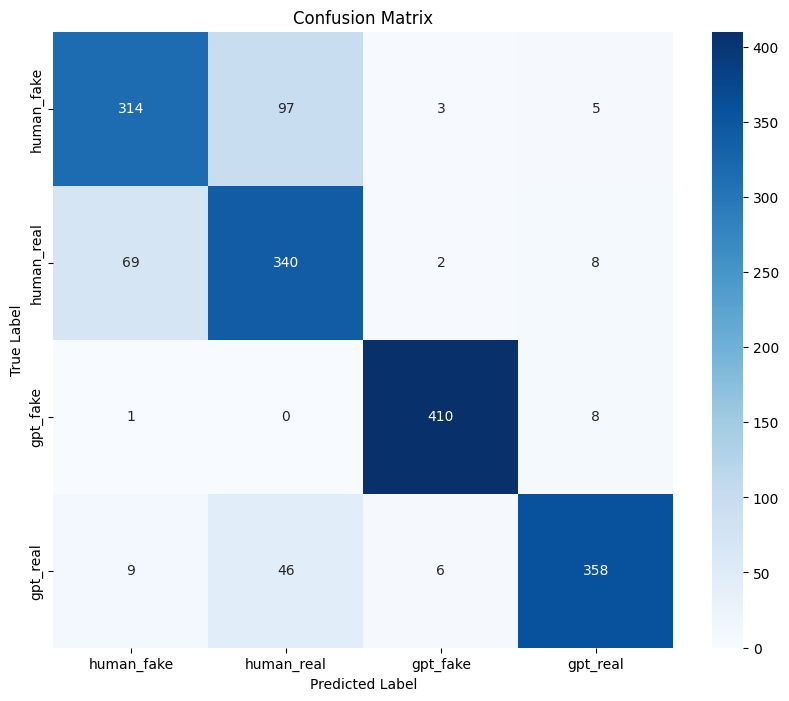

In [ ]:
plt.figure(figsize=(10, 8))
cm = confusion_matrix(results_df['label'], results_df['final_pred'],
                      labels=['human_fake', 'human_real', 'gpt_fake', 'gpt_real'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['human_fake', 'human_real', 'gpt_fake', 'gpt_real'],
            yticklabels=['human_fake', 'human_real', 'gpt_fake', 'gpt_real'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### 5. Confidence Distribution

Text(0.5, 1.0, 'Confidence Distribution')

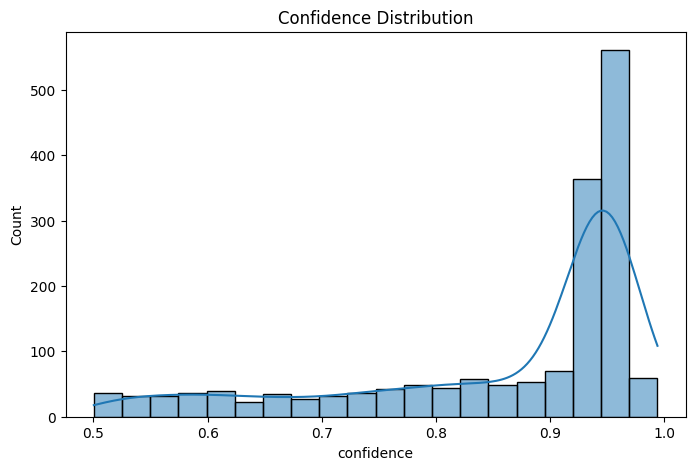

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(results_df['confidence'], bins=20, kde=True)
plt.title('Confidence Distribution')

### 6. Confidence by Prediction Accuracy

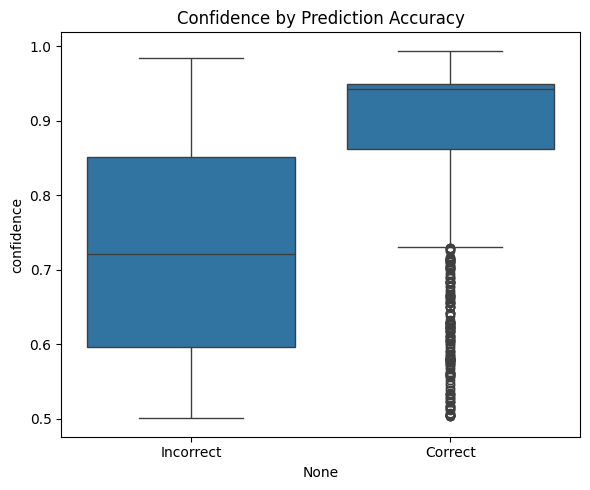

In [ ]:
plt.figure(figsize=(6, 5))
correct = results_df['label'] == results_df['final_pred']
sns.boxplot(x=correct, y=results_df['confidence'])
plt.title('Confidence by Prediction Accuracy')
plt.xticks([0, 1], ['Incorrect', 'Correct'])
plt.tight_layout()
plt.show()

### 7. Confidence vs Error Rate

In [ ]:
# Drop rows with missing confidence or prediction
results_df = results_df.dropna(subset=["confidence", "final_pred"])

# Calculate whether the prediction is correct
results_df['correct'] = results_df['label'] == results_df['final_pred']

# Group by confidence bins
results_df['confidence_bin'] = pd.cut(results_df['confidence'], bins=10)

# Compute error rate and average confidence per bin
bin_stats = results_df.groupby('confidence_bin').agg(
    error_rate=('correct', lambda x: 1 - x.mean()),
    avg_confidence=('confidence', 'mean'),
    count=('confidence', 'count')
).reset_index()

# Visualization
plt.figure(figsize=(10, 6))
sns.lineplot(data=bin_stats, x="avg_confidence", y="error_rate", marker="o")
plt.xlabel("Average Confidence")
plt.ylabel("Error Rate (1 - Accuracy)")
plt.title("Confidence vs Error Rate")
plt.grid(True)
plt.show()


<ipython-input-12-f54130ff0dc2>:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_stats = df.groupby('confidence_bin').agg(


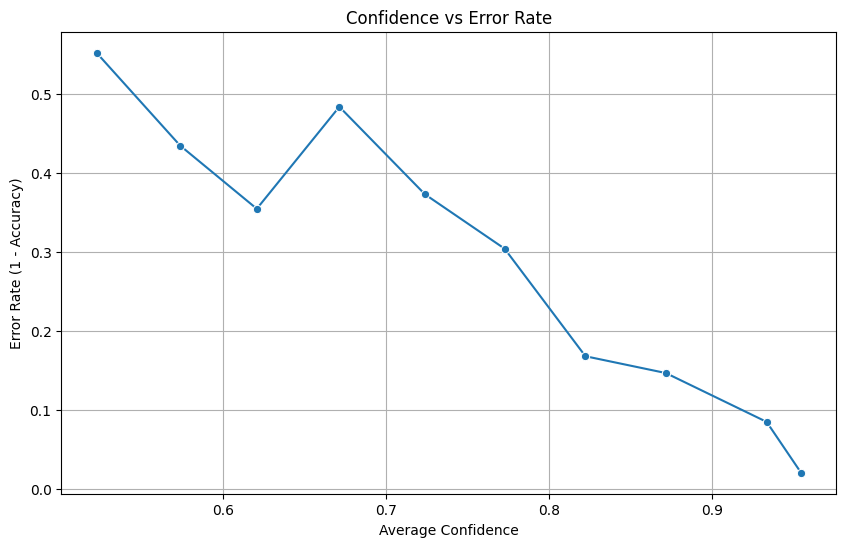

,confidence_bin,error_rate,avg_confidence,count
0,"(0.5, 0.55]",0.552239,0.522251,67
1,"(0.55, 0.599]",0.434783,0.57354,69
2,"(0.599, 0.648]",0.354839,0.620546,62
3,"(0.648, 0.698]",0.483871,0.671169,62
4,"(0.698, 0.747]",0.373134,0.723675,67
5,"(0.747, 0.796]",0.304348,0.772517,92
6,"(0.796, 0.846]",0.168317,0.822079,101
7,"(0.846, 0.895]",0.147059,0.87138,102
8,"(0.895, 0.945]",0.085253,0.93321,434
9,"(0.945, 0.994]",0.020968,0.954308,620


In [ ]:
bin_stats

The confidence vs. error chart shows that the model's predictions become increasingly reliable as confidence increases. In the lower confidence bins (0.5–0.7), the model tends to be overconfident, with error rates often exceeding the average confidence, indicating poor calibration. However, from around 0.75 onward, especially above 0.85, the model demonstrates much better calibration—confidence scores closely reflect actual accuracy. In the highest confidence bin (0.945–0.994), the model achieves excellent performance, with an average confidence of 95.4% and a very low error rate of just 2.1%, suggesting predictions in this range are highly trustworthy.


### Error Propagation Analysis

In [ ]:
print(train_df.columns)

Index(['cleaned_text', 'label', 'stage1_label'], dtype='object')


In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

class ErrorPropagationAnalysis:
    def __init__(self, detector: StrictTwoStageDetector):
        self.detector = detector

    def analyze_stage1_error(self, test_df: pd.DataFrame):
        """
        Analyze Stage 1 error (Human vs GPT classifier).
        """
        # Predict Stage 1
        test_df = self.detector._predict_with_confidence(test_df, stage="stage1")

        # Misclassification rates
        misclassifications = test_df[test_df['stage1_label'].map({'human': 0, 'gpt': 1}) != test_df['stage1_pred']]
        print(f"Misclassified samples in Stage 1: {len(misclassifications)}")

        return misclassifications

    def analyze_stage2_error(self, test_df: pd.DataFrame):
        """
        Analyze Stage 2 error (Veracity classification for both Human and GPT).
        """
        # Ensure veracity label exists
        if 'veracity_label' not in test_df.columns:
            if 'label' in test_df.columns:
                test_df['veracity_label'] = test_df['label']
            else:
                raise KeyError("Missing 'veracity_label' in test_df. Please ensure this column is present.")

        # Predict Stage 1 to get the source predictions
        test_df = self.detector._predict_with_confidence(test_df, stage="stage1")

        # Initialize results
        misclassified_human = []
        misclassified_gpt = []

        # Analyze Stage 2 for human texts
        human_mask = test_df['stage1_pred'] == 0
        if human_mask.any() and self.detector.human_veracity_model is not None:
            human_subset = test_df[human_mask].copy()
            human_subset = self.detector._predict_with_confidence(human_subset, stage="human")

            if 'human_pred' not in human_subset.columns:
                raise KeyError("'human_pred' not found. Ensure the human veracity model returns predictions.")

            # Misclassifications for human veracity
            misclassified_human = human_subset[human_subset['human_pred'] != human_subset['veracity_label']]
            print(f"Misclassified human samples in Stage 2: {len(misclassified_human)}")

        # Analyze Stage 2 for GPT texts
        gpt_mask = test_df['stage1_pred'] == 1
        if gpt_mask.any() and self.detector.gpt_veracity_model is not None:
            gpt_subset = test_df[gpt_mask].copy()
            gpt_subset = self.detector._predict_with_confidence(gpt_subset, stage="gpt")

            if 'gpt_pred' not in gpt_subset.columns:
                raise KeyError("'gpt_pred' not found. Ensure the GPT veracity model returns predictions.")

            # Misclassifications for GPT veracity
            misclassified_gpt = gpt_subset[gpt_subset['gpt_pred'] != gpt_subset['veracity_label']]
            print(f"Misclassified GPT samples in Stage 2: {len(misclassified_gpt)}")

        return misclassified_human, misclassified_gpt


    def analyze_error_propagation(self, test_df: pd.DataFrame):
        """
        Perform error propagation analysis by evaluating Stage 1 and Stage 2 separately.
        """
        print("\n=== Stage 1 Error Analysis ===")
        stage1_misclassifications = self.analyze_stage1_error(test_df)

        print("\n=== Stage 2 Error Analysis (Human + GPT) ===")
        misclassified_human, misclassified_gpt = self.analyze_stage2_error(test_df)

        # Combine the results for a complete view
        total_misclassifications = len(stage1_misclassifications) + len(misclassified_human) + len(misclassified_gpt)
        print(f"Total Misclassified Samples (Stage 1 + Stage 2): {total_misclassifications}")

In [ ]:
error_analysis = ErrorPropagationAnalysis(detector)
error_results = error_analysis.analyze_error_propagation(test_df)

print("Error Analysis Results:", error_results)


=== Stage 1 Error Analysis ===
Misclassified samples in Stage 1: 74

=== Stage 2 Error Analysis (Human + GPT) ===
Misclassified human samples in Stage 2: 876
Misclassified GPT samples in Stage 2: 800
Total Misclassified Samples (Stage 1 + Stage 2): 1750
Error Analysis Results: {'stage1_misclassifications': 74, 'human_stage2_misclassifications': 876, 'gpt_stage2_misclassifications': 800, 'total_misclassifications': 1750}


# Enhanced Model

Compared to the base model, the improved model introduces a two-stage detection pipeline that first classifies whether a news article is AI-generated or human-written, and then applies a source-specific fake news classifier.

Key improvements include:
*   Two-stage architecture: Separates source detection and veracity classification for better specialization.
*   Bias reduction: Addresses misclassification issues, especially for AI-generated fake news.
*   Improved accuracy and F1-score: Each stage is optimized independently, leading to better overall metrics.
*   Data quality control: Added dataset validation to avoid data leakage and ensure clean splits.
*   Better generalization: The model adapts better to both AI and human writing styles, reducing overfitting.














### Modeling

In [ ]:
import os
import json
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from tqdm.auto import tqdm
from typing import List, Dict, Optional, Tuple
import torch


# Custom Trainer that supports weighted loss for class imbalance
class WeightedLossTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights  # Store class weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")

        # Use weighted cross entropy loss if class weights are provided
        if self.class_weights is not None:
            loss_fct = torch.nn.CrossEntropyLoss(weight=self.class_weights.to(model.device))
        else:
            loss_fct = torch.nn.CrossEntropyLoss()  # Default cross entropy loss

        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss


# Custom Dataset class for loading tokenized data
class StrictCustomDataset(Dataset):
    def __init__(self, encodings, labels=None):
        self.encodings = encodings
        self.labels = labels
        if self.labels is not None:
            assert len(self.labels) == len(encodings['input_ids'])  # Ensure labels match the number of examples

    def __getitem__(self, idx):
        item = {k: v[idx].clone().detach() for k, v in self.encodings.items()}  # Clone and detach for safety
        if self.labels is not None:
            item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)  # Add labels to the item
        return item

    def __len__(self):
        return len(self.encodings['input_ids'])  # Return the size of the dataset


# Two-stage model for classifying source and veracity
class BackupAwareTwoStageDetector:
    def __init__(self, model_name="answerdotai/ModernBERT-base"):
        self.model_name = model_name
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)  # Load tokenizer for the chosen model
        self.stage1_model = None  # Placeholder for stage 1 model (source classification)
        self.stage2_primary = None  # Placeholder for primary stage 2 model (veracity classification)
        self.stage2_backup = None  # Placeholder for backup stage 2 model

    def _get_device(self):
        # Return GPU if available, otherwise return CPU
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")

    def tokenize_data(self, texts, max_length=512):
        # Tokenize the text data and return in the required format
        return self.tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt"
        )

    def _compute_metrics(self, eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)  # Convert logits to predicted labels
        precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')  # Calculate metrics
        acc = accuracy_score(labels, preds)  # Calculate accuracy
        return {"accuracy": acc, "precision": precision, "recall": recall, "f1": f1}

    def _compute_class_weights(self, labels):
        # Compute class weights for balancing the loss function
        class_weights = compute_class_weight(
            class_weight='balanced',
            classes=np.unique(labels),
            y=labels
        )
        return torch.tensor(class_weights, dtype=torch.float)  # Return class weights as a tensor

    def train_model(self, train_texts, train_labels, val_texts, val_labels, num_labels, class_weights=None):
        # Tokenize the training and validation texts
        train_enc = self.tokenize_data(train_texts)
        val_enc = self.tokenize_data(val_texts)

        # Create datasets for training and validation
        train_ds = StrictCustomDataset(train_enc, train_labels)
        val_ds = StrictCustomDataset(val_enc, val_labels)

        # Load the model with the specified number of labels for classification
        model = AutoModelForSequenceClassification.from_pretrained(self.model_name, num_labels=num_labels)

        # Initialize the trainer with custom loss and class weights
        trainer = WeightedLossTrainer(
            model=model,
            args=TrainingArguments(
                output_dir="./model_output",  # Directory to save the model outputs
                evaluation_strategy="epoch",  # Evaluate the model at the end of each epoch
                save_strategy="epoch",  # Save the model at the end of each epoch
                learning_rate=2e-5,  # Learning rate for optimization
                per_device_train_batch_size=8,  # Batch size for training
                per_device_eval_batch_size=8,  # Batch size for evaluation
                num_train_epochs=2,  # Number of training epochs
                weight_decay=0.1,  # Weight decay for regularization
                load_best_model_at_end=True,  # Load the best model based on F1 score
                metric_for_best_model="f1",  # Metric used to evaluate the best model
                report_to="none",  # Disable reporting to external systems
                fp16=torch.cuda.is_available()  # Use mixed precision if CUDA is available
            ),
            train_dataset=train_ds,
            eval_dataset=val_ds,
            compute_metrics=self._compute_metrics,
            class_weights=class_weights  # Pass class weights to the trainer
        )
        trainer.train()  # Start training
        return model  # Return the trained model

    def train(self, train_df, val_df):
        print("Training stage1: source classification")

        # Prepare labels for source classification (human vs gpt)
        stage1_labels = train_df['stage1_label'].map({"human": 0, "gpt": 1}).tolist()
        val_stage1_labels = val_df['stage1_label'].map({"human": 0, "gpt": 1}).tolist()

        # Train the first stage model
        self.stage1_model = self.train_model(
            train_df['cleaned_text'].tolist(), stage1_labels,
            val_df['cleaned_text'].tolist(), val_stage1_labels,
            num_labels=2
        )

        print("Predicting stage1 on val set")

        # Make predictions on the validation set using stage 1 model
        stage1_preds, stage1_confs = self.predict(val_df['cleaned_text'].tolist(), self.stage1_model, 2)

        # Add predictions and confidence scores to the validation dataframe
        val_df = val_df.copy()
        val_df['stage1_pred'] = stage1_preds
        val_df['stage1_conf'] = stage1_confs

        # Mask for high confidence predictions (confidence >= 0.85)
        high_conf_mask = val_df['stage1_conf'] >= 0.85
        backup_mask = ~high_conf_mask  # Mask for low confidence predictions

        print("Training stage2: veracity classification")

        # Prepare labels for veracity classification (fake vs real)
        veracity_labels = val_df['label'].str.split('_').str[-1].map({"fake": 0, "real": 1})
        class_weights = self._compute_class_weights(veracity_labels)

        # Train the primary stage 2 model (high confidence predictions)
        self.stage2_primary = self.train_model(
            val_df.loc[high_conf_mask, 'cleaned_text'].tolist(),
            veracity_labels.loc[high_conf_mask].tolist(),
            val_df.loc[high_conf_mask, 'cleaned_text'].tolist(),
            veracity_labels.loc[high_conf_mask].tolist(),
            num_labels=2,
            class_weights=class_weights
        )

        # Train the backup stage 2 model (low confidence predictions)
        self.stage2_backup = self.train_model(
            val_df.loc[backup_mask, 'cleaned_text'].tolist(),
            veracity_labels.loc[backup_mask].tolist(),
            val_df.loc[backup_mask, 'cleaned_text'].tolist(),
            veracity_labels.loc[backup_mask].tolist(),
            num_labels=2,
            class_weights=class_weights
        )

    def predict(self, texts, model, num_labels):
        # Tokenize the input texts
        encodings = self.tokenize_data(texts)
        dataset = StrictCustomDataset(encodings)
        preds, confs = [], []

        model.eval()  # Set model to evaluation mode
        model.to(self._get_device())  # Move model to the appropriate device (GPU/CPU)
        with torch.no_grad():
            # Make predictions without calculating gradients
            for batch in DataLoader(dataset, batch_size=32):
                batch = {k: v.to(self._get_device()) for k, v in batch.items()}
                outputs = model(**batch)
                probs = torch.softmax(outputs.logits, dim=1)  # Apply softmax to get probabilities
                conf, pred = torch.max(probs, dim=1)  # Get the class with the highest probability
                preds.extend(pred.cpu().tolist())  # Collect predictions
                confs.extend(conf.cpu().tolist())  # Collect confidence scores
        return preds, confs  # Return predictions and confidence scores

    def final_predict(self, texts):
        # Make predictions using stage 1 and stage 2 models
        s1_preds, s1_confs = self.predict(texts, self.stage1_model, 2)
        veracity_preds = []

        for i, text in enumerate(texts):
            conf = s1_confs[i]
            # Choose the appropriate stage 2 model based on confidence
            model = self.stage2_primary if conf >= 0.85 else self.stage2_backup
            pred, _ = self.predict([text], model, 2)
            label = "fake" if pred[0] == 0 else "real"  # Convert prediction to label
            source = "human" if s1_preds[i] == 0 else "gpt"  # Determine the source
            veracity_preds.append(f"{source}_{label}")  # Combine source and veracity labels
        return veracity_preds


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
# ======================
# Execution Code
# ======================
# Initialize and train the detector
optimized_detector = BackupAwareTwoStageDetector("answerdotai/ModernBERT-base")

print("Training Stage 1 Model (Human vs GPT Classification)")
optimized_detector.train(train_df, val_df)

# Save path
base_model_name = "ModernBERT-base"
base_save_path = f"/content/drive/MyDrive/Colab Notebooks/W266/FinalProject/model_checkpoints/{base_model_name}"

# Save Stage 1
stage1_path = os.path.join(base_save_path, "Stage1/enhanced")
os.makedirs(stage1_path, exist_ok=True)
optimized_detector.stage1_model.save_pretrained(stage1_path)
optimized_detector.tokenizer.save_pretrained(stage1_path)

# Save Stage 2
stage2_primary_path = os.path.join(base_save_path, "Stage2/primary")
stage2_backup_path = os.path.join(base_save_path, "Stage2/backup")

if optimized_detector.stage2_primary:
    os.makedirs(stage2_primary_path, exist_ok=True)
    optimized_detector.stage2_primary.save_pretrained(stage2_primary_path)

if optimized_detector.stage2_backup:
    os.makedirs(stage2_backup_path, exist_ok=True)
    optimized_detector.stage2_backup.save_pretrained(stage2_backup_path)



tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

Training Stage 1 Model (Human vs GPT Classification)
Training stage1: source classification


config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

... (4 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.312884,0.866137,0.866203,0.866137,0.866144
2,No log,0.253100,0.900367,0.906477,0.900367,0.900090


Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.474494,0.833333,0.694444,0.833333,0.757576
2,No log,0.408652,0.833333,0.694444,0.833333,0.757576


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Analysis

Running final predictions...

Classification Report:
              precision    recall  f1-score   support

    gpt_fake     0.9825    0.9426    0.9621       418
    gpt_real     0.9233    0.8636    0.8925       418
  human_fake     0.9121    0.7201    0.8048       418
  human_real     0.7018    0.9234    0.7975       418

    accuracy                         0.8624      1672
   macro avg     0.8799    0.8624    0.8642      1672
weighted avg     0.8799    0.8624    0.8642      1672



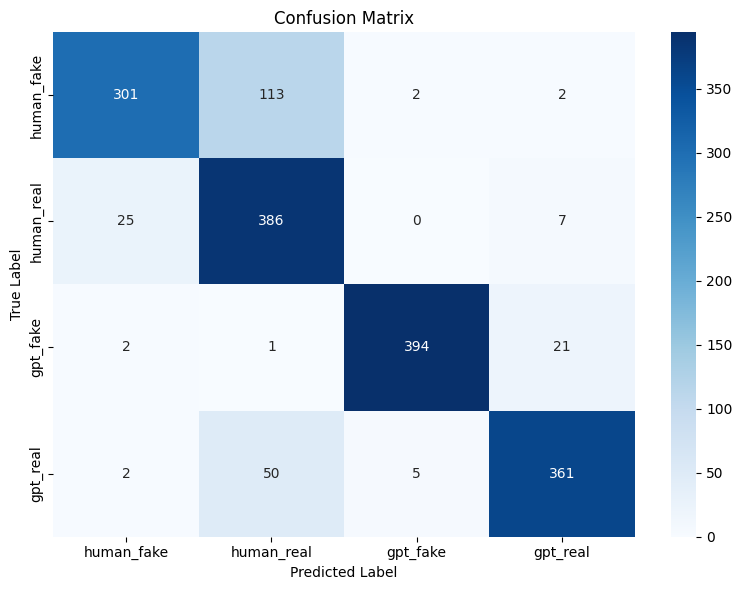

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("Running final predictions...")
texts = val_df['cleaned_text'].tolist()
true_labels = val_df['label'].tolist()
pred_labels = optimized_detector.final_predict(texts)

# Classification Report
print("\nClassification Report:")
print(classification_report(true_labels, pred_labels, digits=4))

# Confusion Matrix
def plot_confusion_matrix(true_labels, pred_labels, labels):
    cm = confusion_matrix(true_labels, pred_labels, labels=labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

# Set label order
all_labels = ['human_fake', 'human_real', 'gpt_fake', 'gpt_real']
plot_confusion_matrix(true_labels, pred_labels, labels=all_labels)
